In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv("placement.csv")

In [3]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


<Axes: ylabel='Density'>

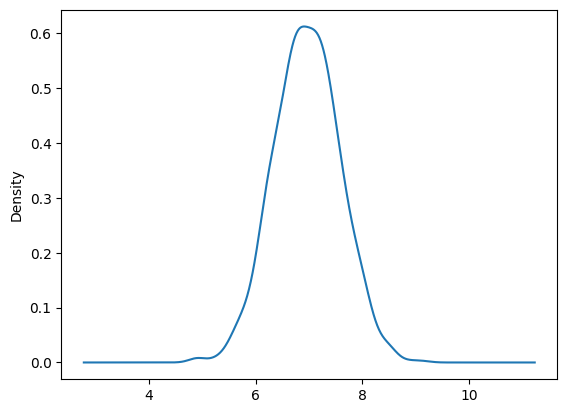

In [5]:
df["cgpa"].plot(kind = "kde")

In [6]:
df['cgpa'].skew()

np.float64(-0.014529938929314918)

In [7]:
print("Mean value of cgpa:",df['cgpa'].mean())
print("Std value of cgpa:",df['cgpa'].std())
print("Min value of cgpa:",df['cgpa'].min())
print("Max value of cgpa:",df['cgpa'].max())

Mean value of cgpa: 6.96124
Std value of cgpa: 0.6158978751323894
Min value of cgpa: 4.89
Max value of cgpa: 9.12


In [8]:
# Finding boundary values 
print("Highest allowed:",df['cgpa'].mean() + 3*df['cgpa'].std())
print("Least allowed:",df['cgpa'].mean() - 3*df['cgpa'].std())

Highest allowed: 8.808933625397168
Least allowed: 5.113546374602832


In [10]:
# Finding the outliers 
df[(df['cgpa'] > 8.80) | (df['cgpa'] < 5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


# Trimming

In [12]:
new_df = df[(df['cgpa'] < 8.80) & (df['cgpa'] > 5.11)]
new_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


In [14]:
# Approach 2 
# Calculating the Zscore 
df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/df['cgpa'].std()
df

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
998,8.62,46.0,1,2.693239


In [16]:
df[df['cgpa_zscore'] > 3]

,cgpa,placement_exam_marks,placed,cgpa_zscore
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062


In [18]:
df[df['cgpa_zscore'] < -3]

,cgpa,placement_exam_marks,placed,cgpa_zscore
485,4.92,44.0,1,-3.314251
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [21]:
# Trimming 
new_df = df[(df['cgpa_zscore'] > -3) & (df['cgpa_zscore'] < 3)]
new_df

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


# Capping

In [22]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [24]:
df['cgpa'] = np.where(
    df['cgpa'] > upper_limit,
    upper_limit, 
    np.where(
        df['cgpa'] < lower_limit, 
        lower_limit, 
        df['cgpa']
    )
)

In [25]:
df.describe()

,cgpa,placement_exam_marks,placed,cgpa_zscore
count,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,6.961499,32.225000,0.489000,-1.474376e-16
std,0.612688,19.130822,0.500129,1.000000e+00
min,5.113546,0.000000,0.000000,-3.362960e+00
25%,6.550000,17.000000,0.000000,-6.677081e-01
50%,6.960000,28.000000,0.000000,-2.013321e-03
75%,7.370000,44.000000,1.000000,6.636815e-01
max,8.808934,100.000000,1.000000,3.505062e+00


In [95]:
from sklearn.preprocessing import PowerTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import r2_score
from sklearn.linear_model import LogisticRegression

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cgpa                  1000 non-null   float64
 1   placement_exam_marks  1000 non-null   float64
 2   placed                1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [72]:
df.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961499,32.225000,0.489000
std,0.612688,19.130822,0.500129
min,5.113546,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,8.808934,100.000000,1.000000


In [67]:
x_train,x_test,y_train,y_test = train_test_split(df.drop(columns='placed'),df['placed'],test_size=0.2,random_state=42)

In [71]:
y_test

521    1
737    1
740    1
660    1
411    0
      ..
408    1
332    0
208    1
613    1
78     0
Name: placed, Length: 200, dtype: int64

In [74]:
pt = PowerTransformer()
x_train_transform = pt.fit_transform(x_train)
x_test_transform = pt.transform(x_test)

In [85]:
clf = DecisionTreeClassifier()
clf.fit(x_train_transform,y_train)
y_pred = clf.predict(x_test_transform)

In [86]:
accuracy_score(y_test,y_pred)

0.485

In [102]:
lr = LogisticRegression()
lr.fit(x_train_transform,y_train)
y_pred2 = lr.predict(x_test_transform)

In [104]:
r2_score(y_test,y_pred2)

-0.8490603959401066

In [105]:
df.corr()

,cgpa,placement_exam_marks,placed
cgpa,1.000000,-0.028623,0.027056
placement_exam_marks,-0.028623,1.000000,-0.025530
placed,0.027056,-0.025530,1.000000
